# Supplementary Figure S7e. *trans*-eQTL loci linked to biomarker-QTL modalities

Sankey plot of the 47,232 *trans*-eQTL loci that also colocalize with at least one biomarker-QTL (after the main-Figure-3a filter: keep *cis*-eQTL loci, and *trans* loci only when also biomarker-QTL). Left: the *trans* layer supporting the locus (*trans*-eProgram only 6,338; both 21,871; *trans*-eGene only 19,023). Right: the biomarker-QTL modality. A locus that colocalizes with k biomarker modalities contributes k flows, so the right-hand total (52,425) exceeds the number of loci. No statistical test is involved.

Input: `data/Figure_S7e_sankey_flows.rds` (`flows`: flow sizes; `trans_layer_summary`: unique loci per left node).

In [1]:
suppressPackageStartupMessages({
  library(ggplot2)
  library(ggalluvial)
})
s7e <- readRDS("data/Figure_S7e_sankey_flows.rds")
s7e$flows
s7e$trans_layer_summary

trans_layer,biomarker,n_loci
<fct>,<fct>,<int>
trans-eProgram,protein-QTL,3158
trans-eProgram,glycoprotein-QTL,3447
trans-eProgram,metabolite-QTL,327
both,protein-QTL,11285
both,glycoprotein-QTL,12035
both,metabolite-QTL,1408
trans-eGene,protein-QTL,9452
trans-eGene,glycoprotein-QTL,10267
trans-eGene,metabolite-QTL,1046


trans_layer,n_loci,proportion
<fct>,<int>,<dbl>
trans-eProgram,6338,0.1341887
both,21871,0.4630547
trans-eGene,19023,0.4027566


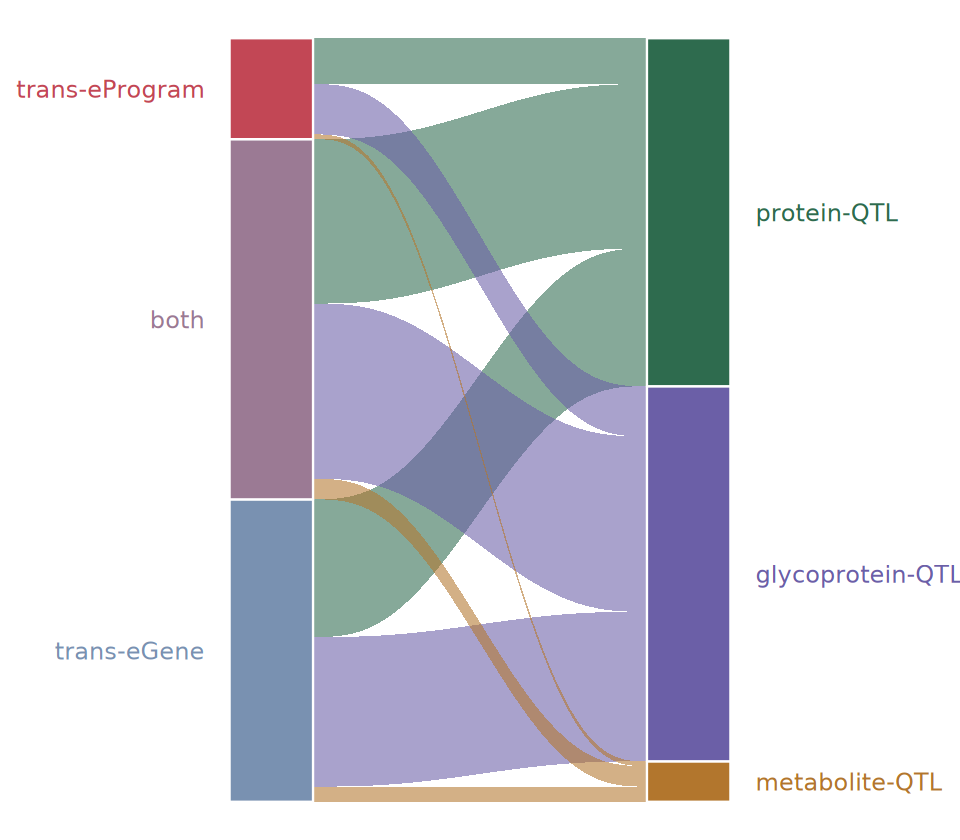

In [2]:
cols <- c("trans-eGene" = "#7991B1", "both" = "#9B7A94", "trans-eProgram" = "#C24755",
          "protein-QTL" = "#2E6B4E", "glycoprotein-QTL" = "#6B5FA7", "metabolite-QTL" = "#B2762D")

p <- ggplot(s7e$flows, aes(axis1 = trans_layer, axis2 = biomarker, y = n_loci)) +
  geom_alluvium(aes(fill = biomarker), width = 0.2, alpha = 0.58, color = NA, curve_type = "quintic") +
  geom_stratum(aes(fill = after_stat(stratum)), width = 0.2, color = "white", linewidth = 0.5) +
  geom_text(stat = "stratum",
            aes(x = after_stat(ifelse(x == 1, x - 0.16, x + 0.16)), label = after_stat(stratum),
                color = after_stat(stratum), hjust = after_stat(ifelse(x == 1, 1, 0))),
            size = 5, show.legend = FALSE) +
  scale_x_discrete(limits = c("trans layer", "biomarker-QTL"), expand = c(0.45, 0.2)) +
  scale_fill_manual(values = cols, guide = "none") +
  scale_color_manual(values = cols, guide = "none") +
  coord_cartesian(clip = "off") +
  theme_void(base_size = 15)

options(repr.plot.width = 8, repr.plot.height = 7)
p